In [286]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [287]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/bigdata/hotel_bookings.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

In [288]:
col = df.columns
for col in col:
  print(df[col].value_counts(),"\n\n")

hotel
City Hotel      236
Resort Hotel    221
Name: count, dtype: int64 


lead_time
57     6
341    6
98     5
219    5
38     5
      ..
235    1
111    1
254    1
206    1
65     1
Name: count, Length: 251, dtype: int64 


arrival_month
Aug    47
Jun    46
Jan    44
Mar    40
Nov    39
Apr    39
Oct    38
May    37
Sep    35
Feb    34
Jul    30
Dec    28
Name: count, dtype: int64 


adults
2     242
3      96
1      74
4      42
20      1
15      1
10      1
Name: count, dtype: int64 


children
0.0    321
1.0     81
2.0     47
Name: count, dtype: int64 


babies
0    436
1     21
Name: count, dtype: int64 


country
GBR    87
JPN    85
KOR    76
CHN    74
FRA    70
USA    58
Name: count, dtype: int64 


market_segment
Online       123
Agent        122
Corporate    108
Offline      104
Name: count, dtype: int64 


deposit_type
No Deposit    159
Non Refund    148
Refundable    146
Name: count, dtype: int64 


customer_type
Transient    159
Contract     150
Group        148
Name: coun

In [289]:
#칼럼 소

In [290]:
# 결측치 최빈값으로 대체
for column in df.columns:
    mode_value = df[column].mode()[0]
    df[column] = df[column].fillna(mode_value)

In [291]:
df=df[df['lead_time'] < 350]
df=df[df['adr'] > 50]
df=df[df['adr'] < 350]

In [292]:

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
columns = ['hotel', 'arrival_month', 'country', 'market_segment', 'deposit_type', 'customer_type']

for col in columns:
    df[col] = le.fit_transform(df[col])



In [293]:
#모든 열을 계산하려면 지우면됨
#df=df[['hotel','arrival_month','deposit_type','previous_cancellations','is_canceled']]

<Axes: >

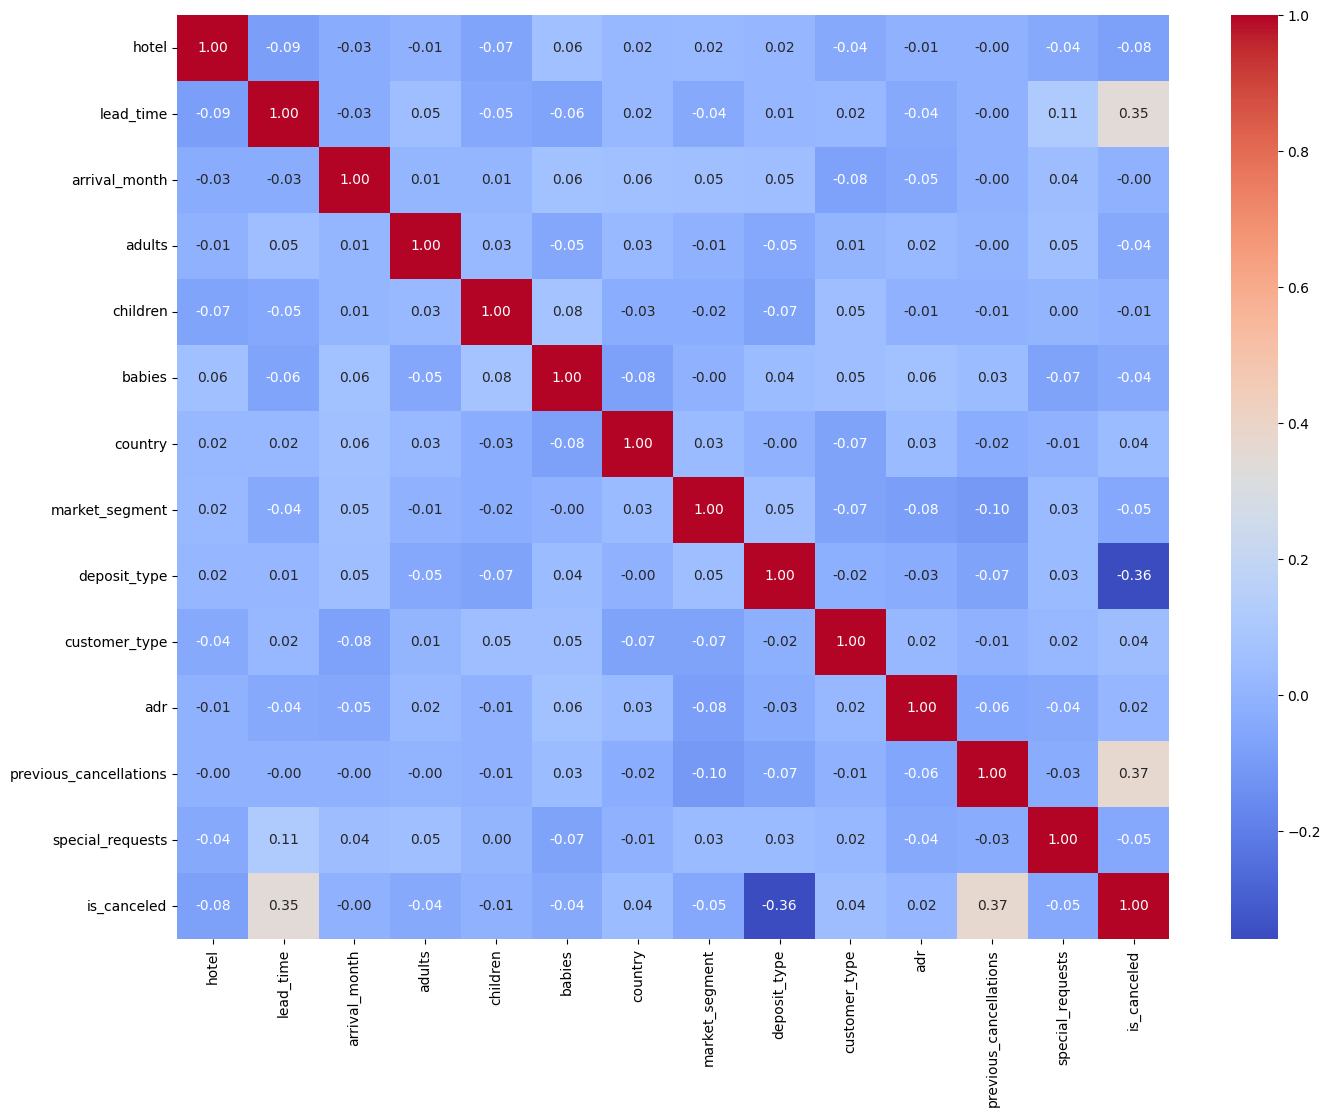

In [294]:
corr=df.corr()
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16,12))
sns.heatmap(
    data=corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm'
)
#leadtime 예약 숙박남은일수 deposite_type 예약금유형 previous_cancellations 과거취소횟수

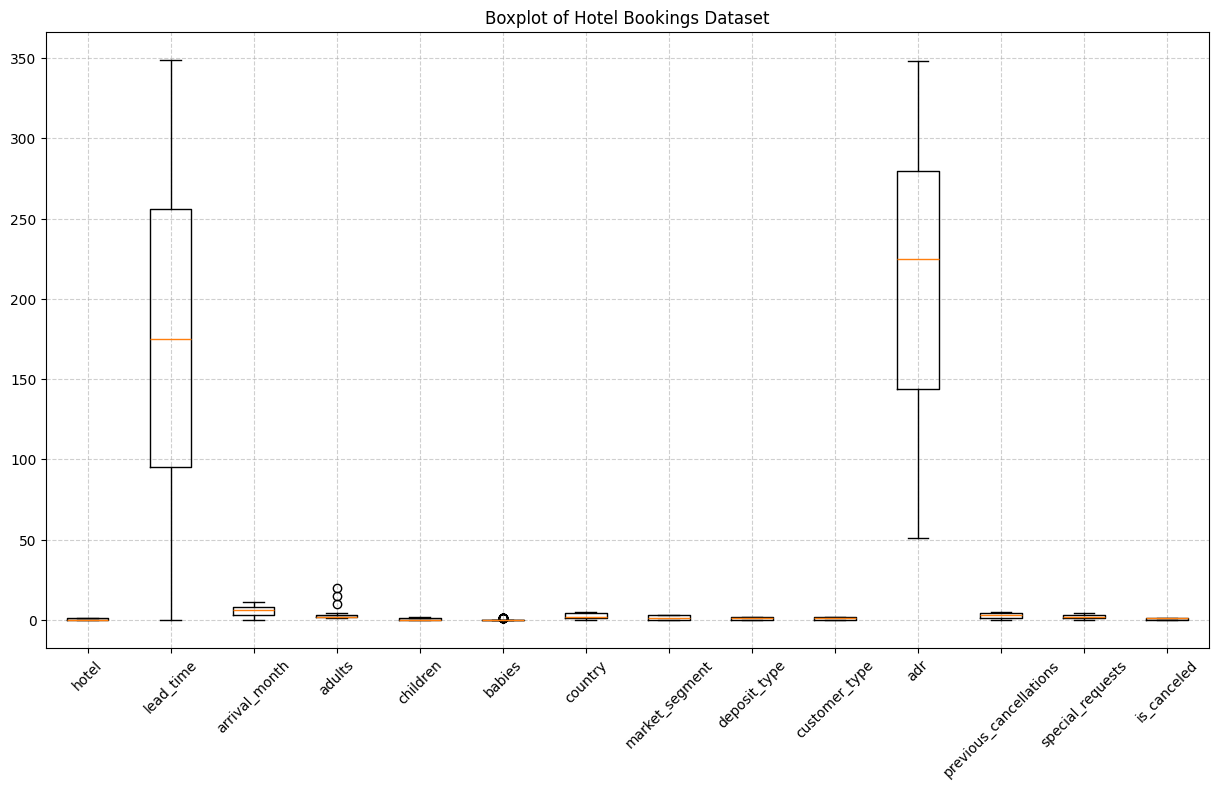

In [295]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
plt.boxplot(df.values, tick_labels=df.columns)
plt.xticks(rotation=45)
plt.title('Boxplot of Hotel Bookings Dataset')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [296]:
df.describe()

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
count,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000,449.000000
mean,0.487751,175.109131,5.483296,2.318486,0.387528,0.046771,2.425390,1.492205,0.964365,1.020045,212.169265,2.594655,2.053452,0.659243
std,0.500407,98.273030,3.458338,1.370493,0.669105,0.211383,1.617255,1.157490,0.820265,0.822154,83.917784,1.671870,1.384478,0.474493
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,51.000000,0.000000,0.000000,0.000000
25%,0.000000,95.000000,3.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,144.000000,1.000000,1.000000,0.000000
50%,0.000000,175.000000,6.000000,2.000000,0.000000,0.000000,2.000000,1.000000,1.000000,1.000000,225.000000,3.000000,2.000000,1.000000
75%,1.000000,256.000000,8.000000,3.000000,1.000000,0.000000,4.000000,3.000000,2.000000,2.000000,280.000000,4.000000,3.000000,1.000000
max,1.000000,349.000000,11.000000,20.000000,2.000000,1.000000,5.000000,3.000000,2.000000,2.000000,348.000000,5.000000,4.000000,1.000000


In [297]:
from sklearn.model_selection import train_test_split

X=df.drop(columns=['is_canceled'])
y=df['is_canceled']

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,stratify=y, test_size=0.3)
print(X_train.shape,X_test.shape)

(314, 13) (135, 13)


In [298]:
from sklearn.preprocessing import StandardScaler

# StandardScaler 클래스의 객체를 올바르게 생성하기 위해 괄호 ()를 추가합니다.
ss = StandardScaler()

X_train_scaled = ss.fit_transform(X_train)
X_test_scaled = ss.transform(X_test)

In [301]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
params={'n_estimators':range(1,55,2),'max_depth':range(1,55,2)}
gs = GridSearchCV(RandomForestClassifier(random_state=42,class_weight='balanced'),params)
gs.fit(X_train_scaled,y_train)



1.0

In [307]:
print(gs.score(X_train_scaled,y_train),gs.score(X_test_scaled,y_test))
gs.param_grid

1.0 0.9629629629629629


{'n_estimators': range(1, 55, 2), 'max_depth': range(1, 55, 2)}

In [308]:
from sklearn.linear_model import LogisticRegression

lo_model =LogisticRegression(n_jobs=3,max_iter=20, random_state=42, class_weight='balanced')
lo_model.fit(X_train_scaled, y_train)
print("로지스틱 회귀 훈련 정확도:", lo_model.score(X_train_scaled, y_train))
print("로지스틱 회귀 테스트 정확도:", lo_model.score(X_test_scaled, y_test))

로지스틱 회귀 훈련 정확도: 0.7898089171974523
로지스틱 회귀 테스트 정확도: 0.7407407407407407


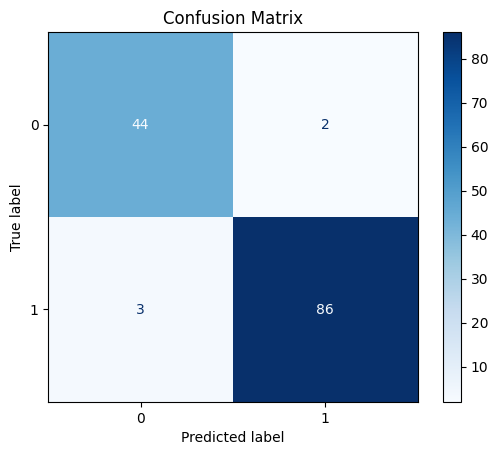

In [309]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred = gs.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.title('Confusion Matrix')
plt.show()